# RandomForestClassifier 7.5km with subbasins

In [1]:
import sys
from pathlib import Path

# Set root
cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.features.preprocessing import load_model_data
from src.evaluation import splits, leakage
from src.evaluation.make_splits import load_split, SPLITS

SPLIT_LIST = list(SPLITS)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss, roc_auc_score


In [2]:
# ===== Settings: change these, then Restart & Run All =====
SPLIT = "7.5km_subbasin"            # "10km", "10km_subbasin", "7.5km_subbasin", "5km_subbasin"
USE_SUBBASIN = True      # True: subbasin features replace elevation
MODEL_SEED = 0
THRESHOLD_MG_L = 10
DROP_ELEVATION = True      # True: remove elevation_m

In [3]:
# Load the cleaned/merged dataset

X, y, meta = load_model_data(subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION)
FEATURES = list(X.columns)

data = load_split(pd.concat([meta, X], axis=1).assign(log_nitrate=y), split=SPLIT)
print(f"split={SPLIT} | subbasin features={USE_SUBBASIN} | {len(FEATURES)} features")
print(data["fold"].value_counts().sort_index().to_dict(), "| holdout rows:", int(data["holdout"].sum()))



split=7.5km_subbasin | subbasin features=True | 59 features
{0: 944, 1: 1114, 2: 1044, 3: 1202, 4: 976} | holdout rows: 976


In [4]:
#create subfolds
from src.models import random_forest
development, X_dev, y_dev = random_forest.make_inner_subfolds(data, FEATURES, N_SUBFOLDS = 4, THRESHOLD_MG_L = 10, SEED = 77)

subfold    0    1    2    3
fold                       
0        246  275  259  164
1        230  187  350  347
2        311  288  212  233
3        212  280  211  499


An exceedance = when a measured nitrate concentration is greater than a specified threshold.

| Metric | Formula | Example result | Interpretation  |
|---|---|---:|---|
| **Accuracy** | $(\frac{TP+TN}{TP+TN+FP+FN})$ | 85% | The model correctly classifies 85% of the wells. However, accuracy can be misleading when exceedances are uncommon. |
| **Precision** | $(\frac{TP}{TP+FP})$ | 60% | Of the wells the model flags as exceedances, 60% actually exceed 10 mg/L. Higher precision means fewer false alarms. |
| **Recall (sensitivity)** | $(\frac{TP}{TP+FN})$ | 75% | The model identifies 75% of all actual exceedances. Higher recall means fewer missed exceedances. |
| **F1-score** | $(2\frac{\text{Precision}\times\text{Recall}}{\text{Precision}+\text{Recall}})$ | 66.7% | Balances precision and recall, penalizing a low value of either. |
| **Specificity** | $(\frac{TN}{TN+FP})$ | 87.5% | The model correctly identifies 87.5% of wells that do not exceed 10 mg/L. |
| **Balanced accuracy** | $(\frac{\text{Recall}+\text{Specificity}}{2})$ | 81.25% | Averages performance on exceedances and non-exceedances, giving both classes equal weight. |
| **ROC-AUC** | Area under the ROC curve | Depends on predictions | Measures how well the model ranks exceedance wells above non-exceedance wells across probability thresholds. |
| **Average precision (AP)** | Weighted summary of precision across recall levels | Depends on predictions | Summarizes the precision-recall trade-off across thresholds. Particularly useful when exceedances are relatively rare. A higher AP generally indicates better performance at identifying exceedances without producing too many false positives. |

In [5]:
model = RandomForestClassifier(n_estimators=50, max_depth=10, max_features='sqrt', random_state=MODEL_SEED, n_jobs=1, class_weight="balanced")

outer_results, oof_results = random_forest.fit_classifier_with_normal_cv(development, X_dev, y_dev, model, THRESHOLD_MG_L = 10,
                                  CLASSIFICATION_THRESHOLD=0.4, PRINT=True)


Overall out-of-fold results:
Average precision: 0.606
ROC-AUC:           0.796
Precision:         0.544
Recall:            0.876
F1:                0.671
Balanced accuracy: 0.741


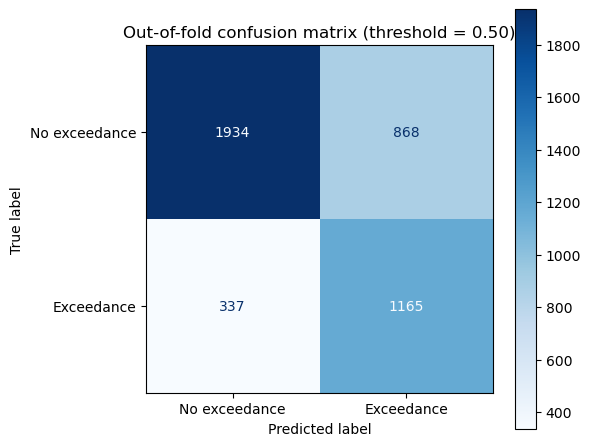

In [6]:
random_forest.plot_confusion_matrix(oof_results, threshold=0.5)

Shows the counts of correctly and incorrectly classified exceedances at chosen probability threshold. 
The model is more likely to count something as an exceedence when it is not. 

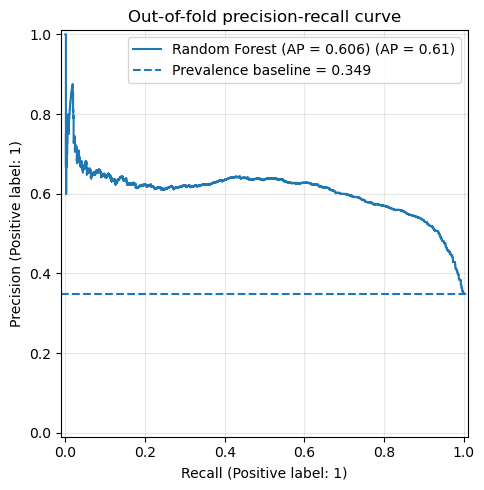

In [7]:
random_forest.plot_precision_recall(oof_results)

Shows the trade-off between precision and recall across probability thresholds. The dashed baseline is the observed prevalence of exceedances.

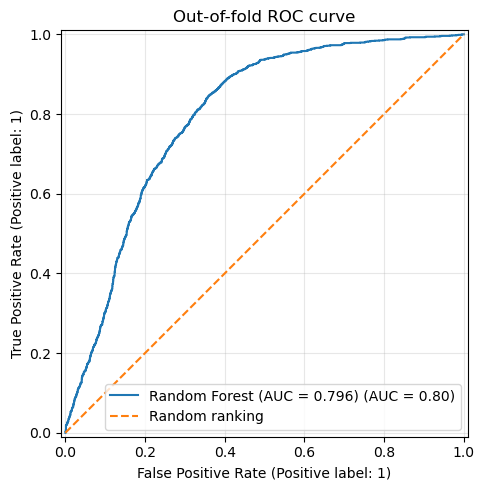

In [8]:
random_forest.plot_roc_curve(oof_results)

Shows the true positive rate against the false positive rate. It provides a complementary view of how well the classifier distinguishes exceedances from non-exceedances.

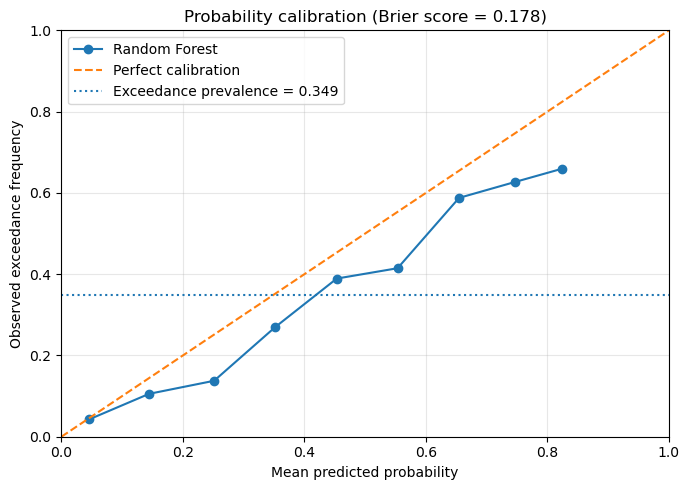

In [9]:
random_forest.plot_calibration_curve(oof_results)

Evaluates whether predicted probabilities agree with observed exceedance frequencies. Points close to the diagonal indicate better calibration.

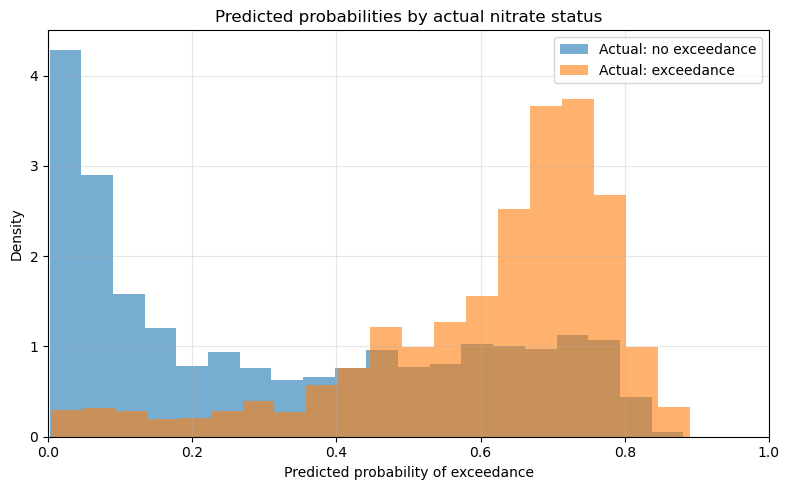

In [10]:
random_forest.plot_probability_distributions(oof_results)

Compares predicted probabilities for actual exceedances versus non-exceedances. Ideally, actual exceedances receive higher predicted probabilities.

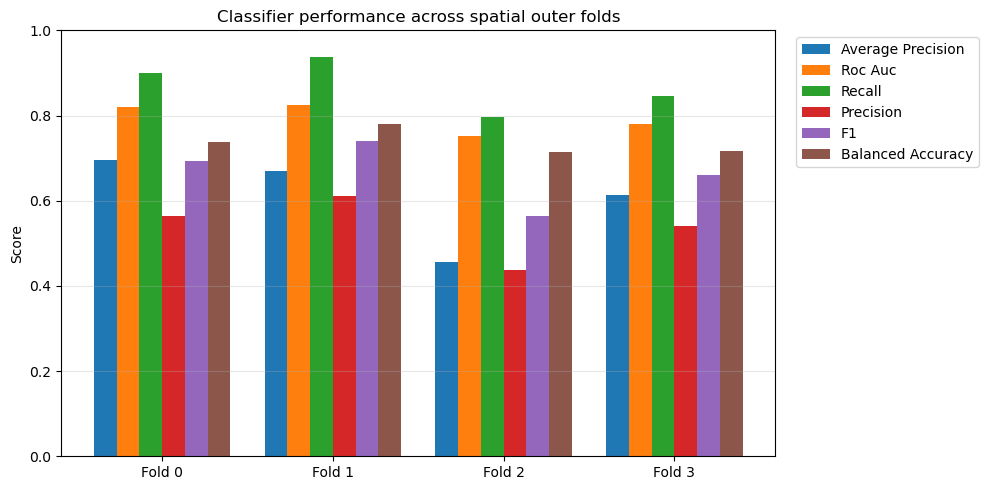

In [11]:
random_forest.plot_outer_fold_metrics(outer_results)

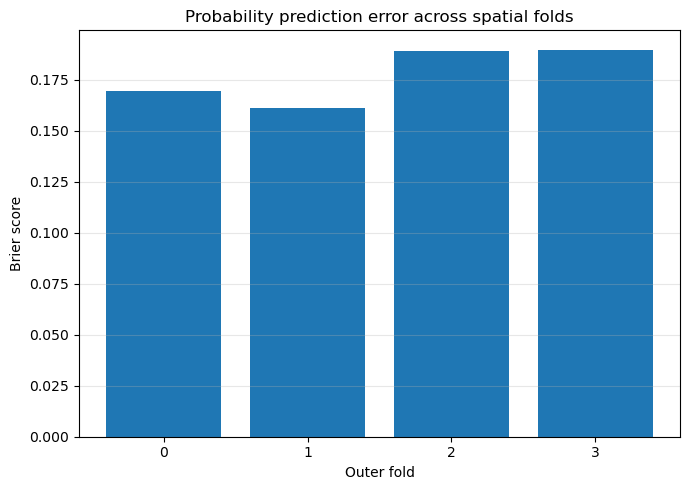

In [12]:
random_forest.plot_outer_fold_brier(outer_results)

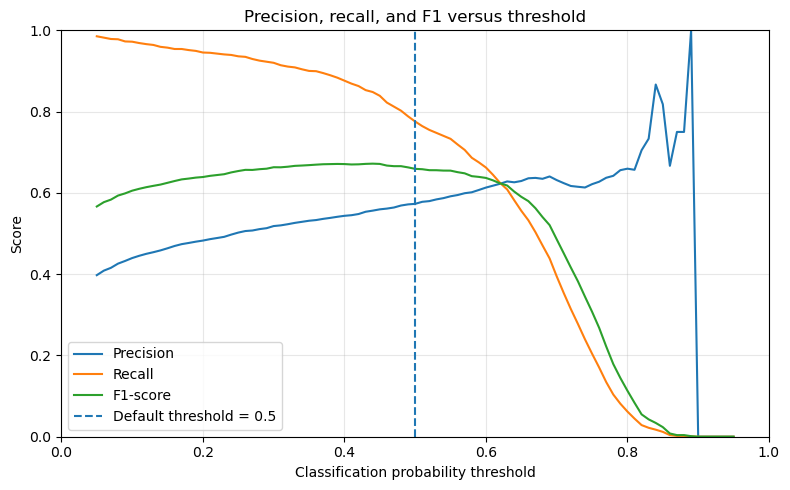

In [13]:
random_forest.plot_threshold_metrics(oof_results)

Precision: “When the model predicts an exceedance, how often is it right?”

Recall: “Of all actual exceedances, how many does the model detect?”

F1 score: “How well does the model balance precision and recall?”

Precision tends to increase as the threshold rises. The model makes fewer positive predictions, but those it does make tend to be more confident.

Recall tends to decrease as the threshold rises. More samples fall below the cutoff, so some actual exceedances are missed.

F1 often peaks somewhere in the middle, where precision and recall have a useful balance. It does not have to peak at 0.5.

Choosing threshold: Find the peak of the F1 curve. 


In [14]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

actual = oof_results["actual"].to_numpy()
prob = oof_results["probability"].to_numpy()

thresholds = np.linspace(0.05, 0.95, 91)
rows = []

for threshold in thresholds:
    predicted = (prob >= threshold).astype(int)

    rows.append({
        "threshold": threshold,
        "precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "f1": f1_score(
            actual, predicted, zero_division=0
        ),
    })

threshold_results = pd.DataFrame(rows)

best_row = threshold_results.loc[threshold_results["f1"].idxmax()]

print(
    threshold_results
    .sort_values("f1", ascending=False)
    .head(10)
    .round(3)
    .to_string(index=False)
)

 threshold  precision  recall    f1
      0.44      0.556   0.848 0.672
      0.43      0.554   0.853 0.671
      0.45      0.560   0.839 0.671
      0.39      0.541   0.883 0.671
      0.40      0.544   0.876 0.671
      0.38      0.538   0.889 0.671
      0.37      0.536   0.895 0.670
      0.42      0.548   0.863 0.670
      0.41      0.545   0.869 0.670
      0.36      0.533   0.899 0.669


Determine hether the default classification threshold of 0.5 is appropriate for identifying nitrate exceedances. 

This suggests that a threshold of 0.4 may improve recall at the cost of some precision. 

In [15]:
for_table = outer_results[["outer_fold", "roc_auc", "brier_score_loss"]]
for_table = for_table.rename(columns={"outer_fold" : "fold", "roc_auc" : "auc", "brier_score_loss" : "brier_skill"})

display(for_table)

,fold,auc,brier_skill
0,0,0.820199,0.169455
1,1,0.823835,0.161035
2,2,0.750937,0.189103
3,3,0.780687,0.189808


In [16]:
from src.evaluation.results_log import save_run, load_runs, summarize


save_run(for_table, model="RandomForestClassifier", task="classification", author="Charlsey",
         split=SPLIT, use_subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION,
         n_features=len(FEATURES))

#The scores table needs a "fold" column plus rmse_log and r2 (regression) or auc and brier_skill (classification).
#Each run is saved as its own small CSV in results/model_runs/ (one file per model and config, 
# so we don't get Git conflicts), so please commit those files too.

#To see everything combined (mean and SD across folds):
#summarize(load_runs(), task="regression")
summarize(load_runs(), task="classification")

Saved 4 folds to results\model_runs\charlsey__randomforestclassifier__classification__7-5km-subbasin__subbasin1__noelev1.csv


auc  \
                                                                                            mean   
task           model                  author   split          use_subbasin drop_elevation          
classification Logistic L1            Andrea   10km_subbasin  True         True            0.799   
                                               5km_subbasin   True         True            0.796   
               Logistic L2            Andrea   10km_subbasin  True         True            0.791   
                                               5km_subbasin   True         True            0.792   
               RandomForestClassifier Charlsey 10km           False        False           0.790   
                                               10km_subbasin  True         True            0.823   
                                               7.5km_subbasin True         True            0.794   

                                                                                                  \
                                                                                             std   
task           model                  author   split          use_subbasin drop_elevation          
classification Logistic L1            Andrea   10km_subbasin  True         True            0.035   
                                               5km_subbasin   True         True            0.023   
               Logistic L2            Andrea   10km_subbasin  True         True            0.031   
                                               5km_subbasin   True         True            0.025   
               RandomForestClassifier Charlsey 10km           False        False           0.033   
                                               10km_subbasin  True         True            0.033   
                                               7.5km_subbasin True         True            0.035   

                                                                                          brier_skill  \
                                                                                                 mean   
task           model                  author   split          use_subbasin drop_elevation               
classification Logistic L1            Andrea   10km_subbasin  True         True                 0.228   
                                               5km_subbasin   True         True                 0.226   
               Logistic L2            Andrea   10km_subbasin  True         True                 0.206   
                                               5km_subbasin   True         True                 0.216   
               RandomForestClassifier Charlsey 10km           False        False                0.181   
                                               10km_subbasin  True         True                 0.163   
                                               7.5km_subbasin True         True                 0.177   

                                                                                                  
                                                                                             std  
task           model                  author   split          use_subbasin drop_elevation         
classification Logistic L1            Andrea   10km_subbasin  True         True            0.066  
                                               5km_subbasin   True         True            0.051  
               Logistic L2            Andrea   10km_subbasin  True         True            0.041  
                                               5km_subbasin   True         True            0.049  
               RandomForestClassifier Charlsey 10km           False        False           0.022  
                                               10km_subbasin  True         True            0.017  
                                               7.5km_subbasin True         True            0.014